In [1]:

# Cell 1 — Analytical Class-E design + EPC2037 GaN model

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# --------------------------------------------------
# Supply and operating specifications
# --------------------------------------------------

V_DD, P_out, f0 = 4.85, 1.65, 14.0e6

w0 = 2*np.pi*f0
T = 1/f0
T_half = T/2

# --------------------------------------------------
# EPC2037 datasheet parameters
# --------------------------------------------------

V_DS_max = 100.0
I_D_max = 1.7

R_on_typ = 0.400
R_on_max = 0.550

V_GS_drive = 5.0
Q_G = 115e-12

C_OSS_50V = 6.5e-12
C_OSS_TR = 12e-12
Q_OSS_50V = 600e-12

# First-order constant-Coss approximation
C_oss_device = C_OSS_TR

# Gate-drive power drawn from the 5 V supply
P_gate = Q_G * V_GS_drive * f0

# --------------------------------------------------
# Analytical ideal Class-E coefficients
# --------------------------------------------------

a = 2 / np.sqrt(np.pi**2 + 4)
phi = np.pi - np.arctan(2/np.pi)

K_R = 2*a**2
K_C = 2*a**2/np.pi

# Derive K_L from the fundamental Fourier component
R_norm = K_R
I_R_norm = np.sqrt(2/R_norm)
I_DC_norm = a*I_R_norm
C_norm = K_C/R_norm

theta = np.linspace(0, 2*np.pi, 200001)
v_D_norm = np.zeros_like(theta)

off = theta >= np.pi
th = theta[off]

v_D_norm[off] = (
    I_DC_norm*(th-np.pi)
    + I_R_norm*(
        np.cos(th+phi)-np.cos(np.pi+phi)
    )
) / C_norm

V1 = np.trapezoid(
    v_D_norm*np.exp(-1j*theta), theta
) / np.pi

I1 = I_R_norm*np.exp(1j*(phi-np.pi/2))

Z1 = V1/I1
K_L = Z1.imag/Z1.real

# --------------------------------------------------
# Classical reference values
# --------------------------------------------------

K_R_ref = 0.5768
K_C_ref = 0.1836
K_L_ref = 1.1525

print("ANALYTICAL CLASS-E COEFFICIENTS")
print("--------------------------------")

for name, value, ref in [
    ("K_R", K_R, K_R_ref),
    ("K_C", K_C, K_C_ref),
    ("K_L", K_L, K_L_ref)
]:
    print(f"{name} = {value:.8f} | reference = {ref:.8f} | "
          f"error = {100*(value/ref-1):+.5f}%")

print(f"a = {a:.8f}")
print(f"phi = {np.degrees(phi):.6f} degrees")

# --------------------------------------------------
# Ideal Class-E component values
# --------------------------------------------------

R_opt = K_R * V_DD**2 / P_out

C_sh_ideal = K_C / (w0 * R_opt)

L_ser = K_L * R_opt / w0

# --------------------------------------------------
# Include EPC2037 output capacitance
# --------------------------------------------------

C_external = C_sh_ideal - C_oss_device

if C_external <= 0:
    raise ValueError("Device Coss exceeds the required shunt capacitance")

# Total drain-node capacitance remains the analytical target
C_sh = C_external + C_oss_device

# --------------------------------------------------
# Sokal reference operating point
# --------------------------------------------------

I_DC_sk = P_out / V_DD
I_R = np.sqrt(2*P_out/R_opt)
phi_sk = phi

# --------------------------------------------------
# Finite-Q output tank
# --------------------------------------------------

Q_L = 3.0

L_1 = L_ser
L_2 = Q_L * R_opt / w0
C_2 = 1 / (w0**2 * L_2)

L_total = L_1 + L_2

# --------------------------------------------------
# Diagnostics
# --------------------------------------------------

print("\nPHYSICAL COMPONENT VALUES")
print("-------------------------")
print(f"R_opt = {R_opt:.3f} Ω")
print(f"C_sh ideal = {C_sh_ideal*1e12:.2f} pF")
print(f"C_external = {C_external*1e12:.2f} pF")
print(f"C_OSS model = {C_oss_device*1e12:.2f} pF")
print(f"C_sh total = {C_sh*1e12:.2f} pF")

print(f"L_1 = {L_1*1e9:.2f} nH   (Sokal L_ser)")
print(f"L_2 = {L_2*1e9:.2f} nH   (tank L, Q_L = {Q_L})")
print(f"C_2 = {C_2*1e12:.2f} pF")
print(f"L_total = L_1 + L_2 = {L_total*1e9:.2f} nH")

print(f"Tank resonance check: L_2 · C_2 · ω0² = "
      f"{L_2*C_2*w0**2:.6f}  (should be 1.000)")

print(f"Sokal: I_DC = {I_DC_sk*1e3:.2f} mA, "
      f"I_R = {I_R*1e3:.2f} mA, "
      f"φ = {np.degrees(phi_sk):.2f}°")

print("\nEPC2037 MODEL")
print("-------------")
print(f"R_DS(on), typical = {R_on_typ*1e3:.0f} mΩ")
print(f"R_DS(on), maximum = {R_on_max*1e3:.0f} mΩ")
print(f"V_DS maximum = {V_DS_max:.1f} V")
print(f"I_D continuous rating = {I_D_max:.2f} A")
print(f"Q_G = {Q_G*1e12:.1f} pC")
print(f"Gate drive voltage = {V_GS_drive:.1f} V")
print(f"Gate drive power = {P_gate*1e3:.2f} mW")

print(f"\nC_OSS at 50 V = {C_OSS_50V*1e12:.2f} pF")
print(f"C_OSS(TR) = {C_OSS_TR*1e12:.2f} pF")
print(f"Q_OSS at 50 V = {Q_OSS_50V*1e12:.1f} pC")


ANALYTICAL CLASS-E COEFFICIENTS
--------------------------------
K_R = 0.57680088 | reference = 0.57680000 | error = +0.00015%
K_C = 0.18360142 | reference = 0.18360000 | error = +0.00077%
K_L = 1.15249413 | reference = 1.15250000 | error = -0.00051%
a = 0.53702927
phi = 147.518363 degrees

PHYSICAL COMPONENT VALUES
-------------------------
R_opt = 8.223 Ω
C_sh ideal = 253.83 pF
C_external = 241.83 pF
C_OSS model = 12.00 pF
C_sh total = 253.83 pF
L_1 = 107.73 nH   (Sokal L_ser)
L_2 = 280.44 nH   (tank L, Q_L = 3.0)
C_2 = 460.83 pF
L_total = L_1 + L_2 = 388.17 nH
Tank resonance check: L_2 · C_2 · ω0² = 1.000000  (should be 1.000)
Sokal: I_DC = 340.21 mA, I_R = 633.50 mA, φ = 147.52°

EPC2037 MODEL
-------------
R_DS(on), typical = 400 mΩ
R_DS(on), maximum = 550 mΩ
V_DS maximum = 100.0 V
I_D continuous rating = 1.70 A
Q_G = 115.0 pC
Gate drive voltage = 5.0 V
Gate drive power = 8.05 mW

C_OSS at 50 V = 6.50 pF
C_OSS(TR) = 12.00 pF
Q_OSS at 50 V = 600.0 pC


In [2]:
# Cell 2

def sokal_waveforms(theta):
    theta = np.asarray(theta)
    v_D = np.zeros_like(theta, dtype=float)
    i_sw = np.zeros_like(theta, dtype=float)
    i_L = I_R * np.sin(theta + phi_sk)
    on  = (theta % (2*np.pi)) < np.pi
    off = ~on
    i_sw[on] = I_DC_sk - i_L[on]
    th = theta[off]
    th_local = th % (2*np.pi)
    dt = (th_local - np.pi) / w0
    v_D[off] = (1.0/C_sh) * (
        I_DC_sk * dt + (I_R/w0)*(np.cos(th_local+phi_sk) - np.cos(np.pi+phi_sk))
    )
    return dict(v_D=v_D, i_sw=i_sw, i_L=i_L)

theta = np.linspace(0, 2*np.pi, 1000, endpoint=False)
sokal = sokal_waveforms(theta)

In [3]:
# Cell 3

def make_f_on(I_DC, R_on):
    def f(t, y):
        i_L, v_C2 = y
        v_D = R_on * (I_DC - i_L)
        return [(v_D - v_C2 - R_opt*i_L) / L_total, i_L / C_2]
    return f

def make_f_off(I_DC):
    def f(t, y):
        v_D, i_L, v_C2 = y
        return [(I_DC - i_L) / C_sh, (v_D - v_C2 - R_opt*i_L) / L_total, i_L / C_2]
    return f

def honest_cycle(I_DC, R_on=0.0, n_warmup=500, n_samples=500):
    f_on  = make_f_on(I_DC, R_on)
    f_off = make_f_off(I_DC)
    i_L, v_C2 = 0.0, 0.0
    sol_on = sol_off = None
    for _ in range(n_warmup):
        sol_on = solve_ivp(f_on, [0, T_half], [i_L, v_C2],
                           method='LSODA', rtol=1e-10, atol=1e-13, dense_output=True)
        i_L, v_C2 = sol_on.y[0,-1], sol_on.y[1,-1]
        v_D_end_on = R_on * (I_DC - i_L)
        sol_off = solve_ivp(f_off, [0, T_half], [v_D_end_on, i_L, v_C2],
                            method='LSODA', rtol=1e-10, atol=1e-13, dense_output=True)
        i_L, v_C2 = sol_off.y[1,-1], sol_off.y[2,-1]

    t_on  = np.linspace(0, T_half, n_samples, endpoint=False)
    t_off = np.linspace(0, T_half, n_samples, endpoint=False)
    i_L_on  = sol_on.sol(t_on)[0]
    v_D_on  = R_on * (I_DC - i_L_on) if R_on > 0 else np.zeros_like(t_on)
    v_D_off = sol_off.sol(t_off)[0]
    i_L_off = sol_off.sol(t_off)[1]

    t_full    = np.concatenate([t_on, T_half + t_off])
    v_D_full  = np.concatenate([v_D_on, v_D_off])
    i_L_full  = np.concatenate([i_L_on, i_L_off])
    i_sw_full = np.concatenate([I_DC - i_L_on, np.zeros_like(i_L_off)])

    return dict(t=t_full, v_D=v_D_full, i_L=i_L_full, i_sw=i_sw_full,
                v_D_avg=np.trapezoid(v_D_full, t_full) / T,
                v_D_peak=v_D_full.max(),
                v_D_turnon=v_D_off[-1],
                i_L_turnon=i_L_off[-1])

def solve_steady_state(R_on=0.0):
    # Convergence sanity: compare 500 vs 1000 warmup
    for I_test in (0.7*I_DC_sk, I_DC_sk, 1.3*I_DC_sk):
        h1 = honest_cycle(I_test, R_on, n_warmup=500)
        h2 = honest_cycle(I_test, R_on, n_warmup=1000)
        delta = abs(h2['v_D_avg'] - h1['v_D_avg'])
        if delta > 1e-3:
            print(f"  WARN: I={I_test*1e3:.0f} mA, <v_D> moves {delta*1e3:.2f} mV between 500 and 1000 warmups")

    def resid(I):
        return honest_cycle(I, R_on, n_warmup=500)['v_D_avg'] - V_DD
    I_sol = brentq(resid, 0.7*I_DC_sk, 1.3*I_DC_sk, xtol=1e-7)
    h = honest_cycle(I_sol, R_on, n_warmup=1000)
    return h, I_sol, h['v_D_avg'] - V_DD

honest, I_DC_h, resid_h = solve_steady_state(R_on_typ)
print(f"I_DC solution   = {I_DC_h*1e3:.3f} mA  (Sokal: {I_DC_sk*1e3:.3f} mA)")
print(f"Residual <v_D>  = {resid_h*1e3:+.4f} mV  (target < 10 mV)")

I_DC solution   = 355.996 mA  (Sokal: 340.206 mA)
Residual <v_D>  = +0.0000 mV  (target < 10 mV)



metric                    |        Ideal |      EPC2037
---------------------------------------------------------
v_D peak (V)              |       17.276 |       18.453
v_D @ turn-on (V)         |       0.0000 |       0.8586
i_L peak (mA)             |        633.5 |        704.4
i_L @ turn-on (mA)        |        340.2 |        207.3

ENERGY BALANCE: EPC2037, Q_L=3.0
-----------------------------------
P_DC supply       =  1726.58 mW
P_gate drive      =     8.05 mW
P_total input     =  1734.63 mW
P_load            =  1616.18 mW
P_Ron             =   108.97 mW
P_ZVS             =     1.31 mW
Drain balance     =   +0.121 mW
Drain efficiency  =    93.61 %
System efficiency =    93.17 %

EPC2037 OPERATING LIMIT CHECK
-----------------------------
Peak drain voltage = 18.45 V / 100.0 V
Peak load current  = 0.704 A / 1.70 A continuous rating
Peak switch current = 0.906 A


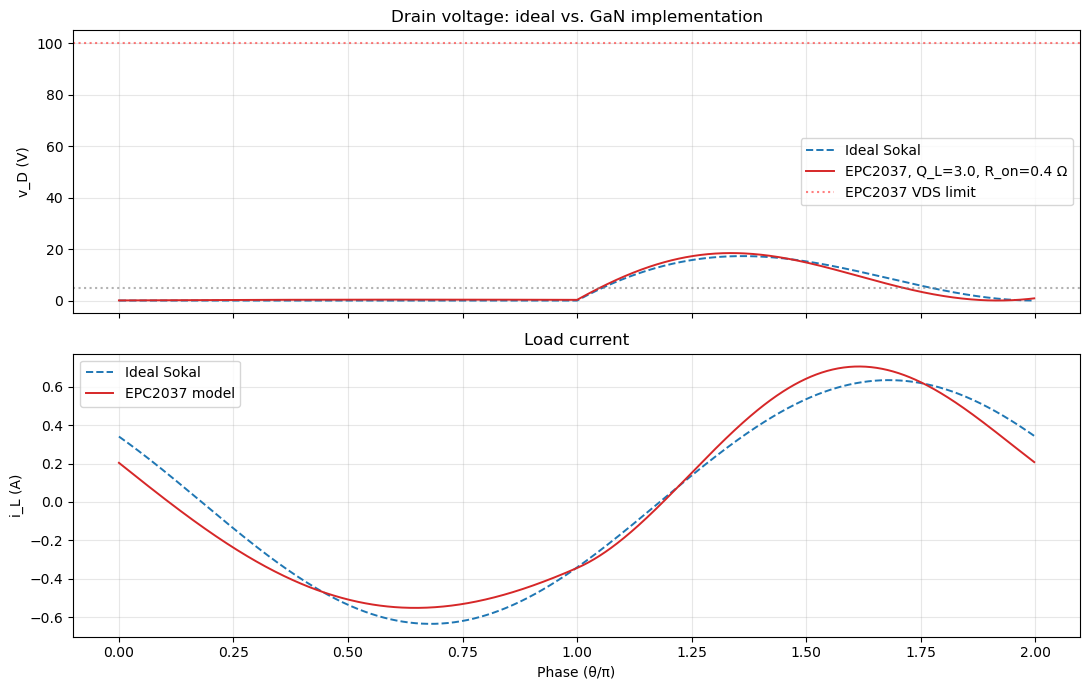

In [4]:

# Cell 4 — EPC2037 performance and energy balance

print(f"\n{'metric':<25} | {'Ideal':>12} | {'EPC2037':>12}")
print("-" * 57)

print(f"{'v_D peak (V)':<25} | "
      f"{sokal['v_D'].max():>12.3f} | "
      f"{honest['v_D_peak']:>12.3f}")

print(f"{'v_D @ turn-on (V)':<25} | "
      f"{sokal['v_D'][0]:>12.4f} | "
      f"{honest['v_D_turnon']:>12.4f}")

print(f"{'i_L peak (mA)':<25} | "
      f"{I_R*1e3:>12.1f} | "
      f"{honest['i_L'].max()*1e3:>12.1f}")

print(f"{'i_L @ turn-on (mA)':<25} | "
      f"{I_R*np.sin(phi_sk)*1e3:>12.1f} | "
      f"{honest['i_L_turnon']*1e3:>12.1f}")

# --------------------------------------------------
# Power calculations
# --------------------------------------------------

P_load_0 = np.trapezoid(
    honest['i_L']**2 * R_opt, honest['t']
) / T

P_Ron_0 = R_on_typ * np.trapezoid(
    honest['i_sw']**2, honest['t']
) / T

P_ZVS_0 = (
    0.5 * C_sh * honest['v_D_turnon']**2 * f0
)

P_in_0 = V_DD * I_DC_h

P_total_0 = P_in_0 + P_gate

eta_drain = P_load_0 / P_in_0
eta_system = P_load_0 / P_total_0

balance_0 = P_in_0 - P_load_0 - P_Ron_0 - P_ZVS_0

print(f"\nENERGY BALANCE: EPC2037, Q_L={Q_L}")
print("-----------------------------------")
print(f"P_DC supply       = {P_in_0*1e3:8.2f} mW")
print(f"P_gate drive      = {P_gate*1e3:8.2f} mW")
print(f"P_total input     = {P_total_0*1e3:8.2f} mW")
print(f"P_load            = {P_load_0*1e3:8.2f} mW")
print(f"P_Ron             = {P_Ron_0*1e3:8.2f} mW")
print(f"P_ZVS             = {P_ZVS_0*1e3:8.2f} mW")
print(f"Drain balance     = {balance_0*1e3:+8.3f} mW")
print(f"Drain efficiency  = {eta_drain*100:8.2f} %")
print(f"System efficiency = {eta_system*100:8.2f} %")

# --------------------------------------------------
# GaN rating checks
# --------------------------------------------------

print("\nEPC2037 OPERATING LIMIT CHECK")
print("-----------------------------")
print(f"Peak drain voltage = {honest['v_D_peak']:.2f} V "
      f"/ {V_DS_max:.1f} V")

print(f"Peak load current  = {honest['i_L'].max():.3f} A "
      f"/ {I_D_max:.2f} A continuous rating")

print(f"Peak switch current = {honest['i_sw'].max():.3f} A")

# --------------------------------------------------
# Waveforms
# --------------------------------------------------

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax[0].plot(
    theta/np.pi, sokal['v_D'],
    'C0--', lw=1.4, label='Ideal Sokal'
)

ax[0].plot(
    honest['t']/T_half, honest['v_D'],
    'C3-', lw=1.4,
    label=f'EPC2037, Q_L={Q_L}, R_on={R_on_typ} Ω'
)

ax[0].axhline(V_DD, color='gray', ls=':', alpha=0.6)
ax[0].axhline(V_DS_max, color='red', ls=':', alpha=0.5,
              label='EPC2037 VDS limit')

ax[0].set_ylabel('v_D (V)')
ax[0].legend()
ax[0].grid(alpha=0.3)
ax[0].set_title('Drain voltage: ideal vs. GaN implementation')

ax[1].plot(
    theta/np.pi, sokal['i_L'],
    'C0--', lw=1.4, label='Ideal Sokal'
)

ax[1].plot(
    honest['t']/T_half, honest['i_L'],
    'C3-', lw=1.4, label='EPC2037 model'
)

ax[1].set_xlabel('Phase (θ/π)')
ax[1].set_ylabel('i_L (A)')
ax[1].legend()
ax[1].grid(alpha=0.3)
ax[1].set_title('Load current')

plt.tight_layout()
plt.show()



 R_on |    I_DC |  v_Dpk |  v_D@on |  P_load |  P_Ron |  P_ZVS |    P_in |  balance |   eff |    resid
---------------------------------------------------------------------------------------------------------
 0.00 |   377.6 |  19.36 |  +0.513 |  1830.6 |    0.0 |    0.5 |  1831.3 |    +0.27 | 100.0% |   -0.00
 0.10 |   371.9 |  19.12 |  +0.604 |  1773.2 |   29.8 |    0.6 |  1803.9 |    +0.26 | 98.3% |   -0.00
 0.20 |   366.5 |  18.89 |  +0.691 |  1718.5 |   57.8 |    0.8 |  1777.4 |    +0.23 | 96.7% |   +0.00
 0.40 |   356.0 |  18.45 |  +0.859 |  1616.2 |  109.0 |    1.3 |  1726.6 |    +0.12 | 93.6% |   +0.00
 0.60 |   346.1 |  18.04 |  +1.016 |  1522.5 |  154.3 |    1.8 |  1678.6 |    -0.04 | 90.7% |   -0.00
 0.80 |   336.8 |  17.65 |  +1.164 |  1436.6 |  194.5 |    2.4 |  1633.2 |    -0.24 | 88.0% |   +0.00
 1.00 |   327.9 |  17.28 |  +1.304 |  1357.5 |  230.2 |    3.0 |  1590.3 |    -0.48 | 85.4% |   +0.00


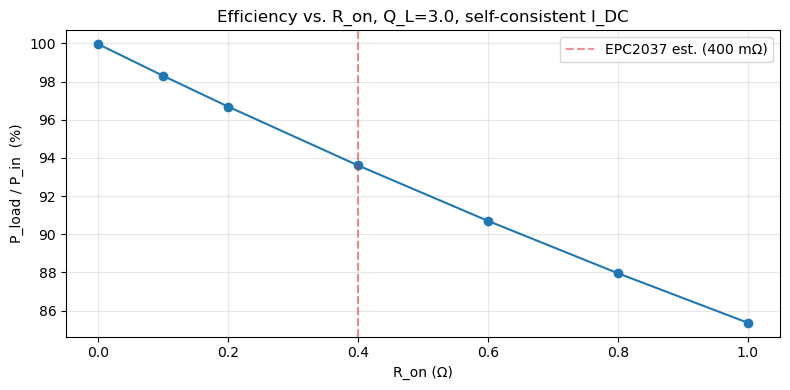

In [5]:
# Cell 5

print(f"\n{'R_on':>5} | {'I_DC':>7} | {'v_Dpk':>6} | {'v_D@on':>7} | "
      f"{'P_load':>7} | {'P_Ron':>6} | {'P_ZVS':>6} | {'P_in':>7} | "
      f"{'balance':>8} | {'eff':>5} | {'resid':>8}")
print("-" * 105)
results = []
for R_on in [0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
    h, I_dc, resid = solve_steady_state(R_on)
    P_load = np.trapezoid((h['i_L']**2) * R_opt, h['t']) / T
    P_Ron  = R_on * np.trapezoid(h['i_sw']**2, h['t']) / T
    P_ZVS  = 0.5 * C_sh * h['v_D_turnon']**2 * f0
    P_in   = V_DD * I_dc
    balance = P_in - P_load - P_Ron - P_ZVS
    eff = P_load / P_in if P_in > 0 else 0
    print(f"{R_on:>5.2f} | {I_dc*1e3:>7.1f} | {h['v_D_peak']:>6.2f} | "
          f"{h['v_D_turnon']:>+7.3f} | {P_load*1e3:>7.1f} | "
          f"{P_Ron*1e3:>6.1f} | {P_ZVS*1e3:>6.1f} | {P_in*1e3:>7.1f} | "
          f"{balance*1e3:>+8.2f} | {100*eff:>4.1f}% | {resid*1e3:>+7.2f}")
    results.append((R_on, eff))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r[0] for r in results], [100*r[1] for r in results], 'o-')
ax.axvline(0.4, color='C3', ls='--', alpha=0.5, label='EPC2037 est. (400 mΩ)')
ax.set_xlabel('R_on (Ω)')
ax.set_ylabel('P_load / P_in  (%)')
ax.set_title(f'Efficiency vs. R_on, Q_L={Q_L}, self-consistent I_DC')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


  R_on |    I_DC |   v_Dpk |   P_load |   P_Ron |  P_gate |     P_in |  eta_sys
-------------------------------------------------------------------------------------
  0.00 |   377.6 |   19.36 |   1830.6 |     0.0 |     8.1 |   1831.3 |   99.52%
  0.10 |   371.9 |   19.12 |   1773.2 |    29.8 |     8.1 |   1803.9 |   97.86%
  0.20 |   366.5 |   18.89 |   1718.5 |    57.8 |     8.1 |   1777.4 |   96.25%
  0.30 |   361.2 |   18.67 |   1666.2 |    84.2 |     8.1 |   1751.6 |   94.69%
  0.40 |   356.0 |   18.45 |   1616.2 |   109.0 |     8.1 |   1726.6 |   93.17%
  0.55 |   348.5 |   18.14 |   1545.2 |   143.5 |     8.1 |   1690.3 |   90.98%
  0.70 |   341.4 |   17.84 |   1478.6 |   175.0 |     8.1 |   1655.6 |   88.88%
  0.85 |   334.5 |   17.56 |   1416.2 |   203.8 |     8.1 |   1622.3 |   86.87%
  1.00 |   327.9 |   17.28 |   1357.5 |   230.2 |     8.1 |   1590.3 |   84.93%


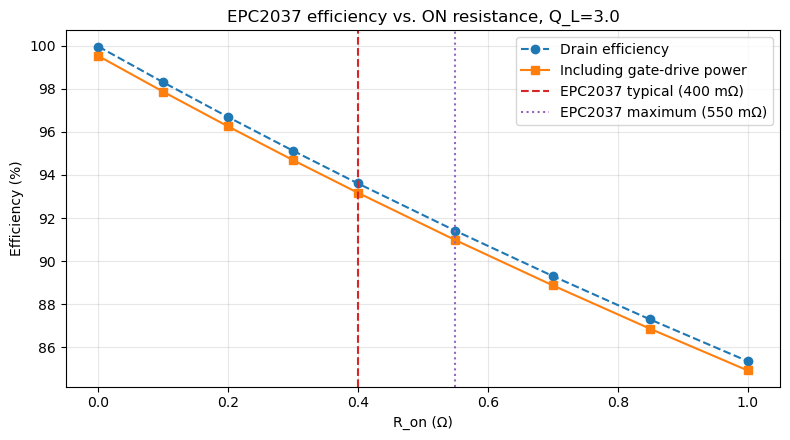

In [6]:

# Cell 6 — EPC2037 efficiency vs. ON resistance

print(
    f"\n{'R_on':>6} | {'I_DC':>7} | {'v_Dpk':>7} | "
    f"{'P_load':>8} | {'P_Ron':>7} | {'P_gate':>7} | "
    f"{'P_in':>8} | {'eta_sys':>8}"
)

print("-" * 85)

results = []

for R_on in [0.0, 0.1, 0.2, 0.3, 0.4, 0.55, 0.7, 0.85, 1.0]:

    h, I_dc, resid = solve_steady_state(R_on)

    P_load = np.trapezoid(
        h['i_L']**2 * R_opt, h['t']
    ) / T

    P_Ron = R_on * np.trapezoid(
        h['i_sw']**2, h['t']
    ) / T

    P_ZVS = 0.5*C_sh*h['v_D_turnon']**2*f0

    P_in = V_DD*I_dc
    P_total = P_in + P_gate

    eta_drain = P_load/P_in
    eta_system = P_load/P_total

    balance = P_in-P_load-P_Ron-P_ZVS

    print(
        f"{R_on:6.2f} | {I_dc*1e3:7.1f} | "
        f"{h['v_D_peak']:7.2f} | {P_load*1e3:8.1f} | "
        f"{P_Ron*1e3:7.1f} | {P_gate*1e3:7.1f} | "
        f"{P_in*1e3:8.1f} | {eta_system*100:7.2f}%"
    )

    results.append((
        R_on, eta_drain, eta_system,
        h['v_D_peak'], h['i_L'].max()
    ))

# --------------------------------------------------
# Efficiency plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    [r[0] for r in results],
    [100*r[1] for r in results],
    'o--', label='Drain efficiency'
)

ax.plot(
    [r[0] for r in results],
    [100*r[2] for r in results],
    's-', label='Including gate-drive power'
)

ax.axvline(
    R_on_typ, color='C3', ls='--',
    label='EPC2037 typical (400 mΩ)'
)

ax.axvline(
    R_on_max, color='C4', ls=':',
    label='EPC2037 maximum (550 mΩ)'
)

ax.set_xlabel('R_on (Ω)')
ax.set_ylabel('Efficiency (%)')
ax.set_title(f'EPC2037 efficiency vs. ON resistance, Q_L={Q_L}')

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
